# ShopSphere Repurchase Prediction: FT-Transformer (PyTorch)
**Course:** IT2226 AI Innovation and Deep Learning Project  
**Task:** predict `target` = 1 (at least one purchase between 1 and 30 Oct 2024)  
**Role in the team:** deep-learning candidate in the 4-way bake-off against LightGBM, MLP+GRU, TabNet and pytorch-tabular.

## What this notebook does
1. Loads the **shared** feature table and the **shared** fold file (so every teammate trains and validates on identical customers).
2. Preprocesses features **inside each fold** (no leakage from validation rows).
3. Builds an **FT-Transformer** from scratch in PyTorch: every feature becomes a "token", and self-attention lets features interact.
4. Trains with 5-fold cross-validation, minimal tuning, early stopping on the validation fold (the same rule as the LightGBM baseline).
5. Evaluates with ROC-AUC, PR-AUC, precision@k, calibration and an F1 threshold sweep, compares against LightGBM fold by fold, and saves everything.

## Before you run
- Runtime menu: **Change runtime type, T4 GPU**.
- Have two files ready (made by the LightGBM notebook after the `late_deliveries_count` fix): `features_v1.parquet` and `folds.csv`.
- **First run: set `"smoke_test": True`** in the CONFIG cell to check the pipeline end to end on fold 0 in about a minute. Then set it back to `False` for the real run.

## Map of the notebook
| Section | What it does |
|---|---|
| 1. Setup and CONFIG | imports, GPU check, every setting in one place |
| 2. Load and sanity checks | reads the data, checks folds, shows missing values |
| 3. Preprocessing | per-fold imputation, log transform, scaling, category indices |
| 4. The model | feature tokenizer, FT-Transformer, forward pass check |
| 5. Training functions | one fold: train loop, early stopping, prediction |
| 6. 5-fold cross-validation | the main loop, saves OOF and test predictions |
| 7. Evaluation | metrics, precision@k, calibration, threshold sweep, curves |
| 8. Compare with LightGBM | fold-by-fold, paired differences |
| 9. Save outputs | OOF file, submission files, experiment log |
| 10. Code review cheat sheet | what depends on what, likely questions |

## 1. Setup and CONFIG

In [1]:
import os, time, json, copy, math, random, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch                 # the core tensor library (like NumPy, but can run on a GPU and tracks gradients)
import torch.nn as nn        # building blocks for neural networks (layers, losses)

from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
                             brier_score_loss, f1_score, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve

print("PyTorch version:", torch.__version__)

# A "device" says where tensors live and where maths runs. Model and data must be on the SAME device.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found")
if device.type == "cpu":
    print("WARNING: running on CPU. In Colab use Runtime > Change runtime type > T4 GPU. It will be much slower.")

PyTorch version: 2.14.1+cu130
Training device: cuda | Tesla T4


In [2]:
# ----------------------------------------------------------------------------------------------
# CONFIG: every setting lives here, so an experiment = one config + one set of results.
# ----------------------------------------------------------------------------------------------
CONFIG = {
    # ---------- files (produced by the LightGBM notebook) ----------
    "features_path": "features_v1.parquet",     # one row per customer, all 80,000, incl. id/target/is_test
    "folds_path":    "folds.csv",              # customer_id, fold  (0..4), shared by the whole team
    "lgbm_oof_path": "oof_lightgbm.csv",       # optional: customer_id, prob  (for the comparison in section 8)

    # ---------- column roles (edit if your feature table differs) ----------
    "id_col": "customer_id",
    "target_col": "target",
    "test_flag_col": "is_test",
    "cat_cols": ["country_code", "customer_tier", "preferred_channel"],
    "binary_cols": ["age_is_missing", "email_open_rate_is_missing", "email_opt_in",
                    "sms_opt_in", "do_not_contact", "is_inactive_90d"],

    # ---------- preprocessing ----------
    "skew_threshold": 1.0,     # numeric columns more skewed than this (and never negative) get log1p
    "clip_value": 5.0,         # after standardising, clip to +/- 5 standard deviations

    # ---------- model ----------
    "d_token": 64,             # size of the vector ("token") that represents each feature
    "n_blocks": 3,             # number of stacked transformer blocks
    "n_heads": 4,              # attention heads per block (d_token must divide by n_heads)
    "ffn_mult": 2,             # hidden size of the feed-forward sub-layer = d_token * ffn_mult
    "dropout": 0.1,

    # ---------- training (minimal tuning: fixed values, no search) ----------
    "lr": 3e-4,
    "weight_decay": 1e-5,
    "batch_size": 512,
    "max_epochs": 60,
    "patience": 8,             # stop if validation score has not improved for this many epochs
    "grad_clip": 1.0,          # cap on the gradient norm, protects against unstable updates
    "early_stop_metric": "roc_auc",   # "roc_auc" or "pr_auc"

    # ---------- experiment control ----------
    "seeds": [42, 43, 44],                     # add 43, 44 later for a more stable estimate
    "folds_to_run": [0, 1, 2, 3, 4],
    "smoke_test": False,               # True = fold 0 only, 3 epochs, just to test the pipeline
    "run_name": "ft_transformer_seeds_42_43_44",
}

if CONFIG["smoke_test"]:
    CONFIG["folds_to_run"] = [0]
    CONFIG["max_epochs"] = 3
    print("SMOKE TEST: fold 0 only, 3 epochs. Results are NOT meaningful.")

assert CONFIG["d_token"] % CONFIG["n_heads"] == 0, "d_token must be divisible by n_heads"
os.makedirs("artifacts", exist_ok=True)
print(json.dumps({k: v for k, v in CONFIG.items() if k not in ("cat_cols", "binary_cols")}, indent=1))

{
 "features_path": "features_v1.parquet",
 "folds_path": "folds.csv",
 "lgbm_oof_path": "oof_lightgbm.csv",
 "id_col": "customer_id",
 "target_col": "target",
 "test_flag_col": "is_test",
 "skew_threshold": 1.0,
 "clip_value": 5.0,
 "d_token": 64,
 "n_blocks": 3,
 "n_heads": 4,
 "ffn_mult": 2,
 "dropout": 0.1,
 "lr": 0.0003,
 "weight_decay": 1e-05,
 "batch_size": 512,
 "max_epochs": 60,
 "patience": 8,
 "grad_clip": 1.0,
 "early_stop_metric": "roc_auc",
 "seeds": [
  42,
  43,
  44
 ],
 "folds_to_run": [
  0,
  1,
  2,
  3,
  4
 ],
 "smoke_test": false,
 "run_name": "ft_transformer_seeds_42_43_44"
}


## 2. Load data and sanity checks
We use the **same feature table and fold file as the whole team**. The checks below catch the usual silent problems: wrong row counts, labels missing, folds not stratified, and a leaked column.

In [3]:
needed = [CONFIG["features_path"], CONFIG["folds_path"]]
missing = [f for f in needed if not os.path.exists(f)]
if missing:
    print("Missing files:", missing, "-> choose them in the upload dialog")
    try:
        from google.colab import files
        files.upload()                      # files land in the current working directory
    except ImportError:
        raise FileNotFoundError(f"Put these files next to the notebook: {missing}")

feat  = pd.read_parquet(CONFIG["features_path"])
folds = pd.read_csv(CONFIG["folds_path"])
ID, TARGET, TESTFLAG = CONFIG["id_col"], CONFIG["target_col"], CONFIG["test_flag_col"]

for c in [ID, TARGET, TESTFLAG]:
    assert c in feat.columns, f"'{c}' not found in features file. Columns: {list(feat.columns)[:10]}..."

# Categoricals may come back from parquet as pandas 'category' dtype. Turn them into plain strings
# so that category -> integer mapping is simple and identical in every fold.
for c in CONFIG["cat_cols"]:
    feat[c] = feat[c].astype("object").where(feat[c].notna(), "unknown").astype(str)

# Labelled rows (train) get their fold from folds.csv. Unlabelled rows (test) are predicted at the end.
train = feat[feat[TESTFLAG] == 0].merge(folds, on=ID, how="inner").reset_index(drop=True)
test  = feat[feat[TESTFLAG] == 1].reset_index(drop=True)
train[TARGET] = train[TARGET].astype(int)

# Columns the model may see: everything except id, label, test flag and fold.
FEATURE_COLS = [c for c in feat.columns if c not in (ID, TARGET, TESTFLAG)]
CAT_COLS, BIN_COLS = CONFIG["cat_cols"], CONFIG["binary_cols"]
for c in CAT_COLS + BIN_COLS:
    assert c in FEATURE_COLS, f"configured column '{c}' is not a feature column"
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS + BIN_COLS]

# ---- sanity checks (each one guards against a silent failure) ----
assert len(train) == len(folds), "some folds.csv customers are not in the labelled data (or vice versa)"
assert train[ID].is_unique, "duplicate customer_id in training data"
assert set(train[TARGET].unique()) <= {0, 1}, "target must be 0/1"
assert set(train["fold"].unique()) == {0, 1, 2, 3, 4}, "expected folds 0..4"
assert not set(train[ID]) & set(test[ID]), "train and test customers overlap"

print(f"Features: {len(FEATURE_COLS)}  (numeric {len(NUM_COLS)}, binary {len(BIN_COLS)}, categorical {len(CAT_COLS)})")
print(f"Train customers: {len(train):,} | positive rate {train[TARGET].mean():.2%} | Test customers: {len(test):,}")
print("\nPositive rate per fold (should be nearly identical = stratified):")
print(train.groupby("fold")[TARGET].agg(["size", "mean"]).round(4).T)

nan_counts = train[NUM_COLS].isna().sum()
print("\nNumeric columns with missing values (these get a 'was missing' flag):")
print(nan_counts[nan_counts > 0].to_string() if (nan_counts > 0).any() else "none")
const = [c for c in NUM_COLS if train[c].nunique() <= 1]
print("\nConstant columns (carry no information, check these!):", const if const else "none")

Features: 47  (numeric 38, binary 6, categorical 3)
Train customers: 64,000 | positive rate 14.57% | Test customers: 16,000

Positive rate per fold (should be nearly identical = stratified):
fold           0           1           2           3           4
size  12800.0000  12800.0000  12800.0000  12800.0000  12800.0000
mean      0.1457      0.1457      0.1457      0.1457      0.1458

Numeric columns with missing values (these get a 'was missing' flag):
age                         3342
email_open_rate            11617
recency_days               24640
days_since_last_session     5173
avg_csat_score             54800

Constant columns (carry no information, check these!): none


## 3. Preprocessing (fitted per fold)
Neural networks are much more sensitive to input scale than trees, so we need to prepare features carefully:

| Step | Why |
|---|---|
| Median-impute missing numerics **and add a "was missing" flag** | NaN breaks neural nets, and *missing* is informative here (for example no tickets means no CSAT score) |
| `log1p` on skewed, non-negative columns | counts and money are heavy-tailed; one whale customer would otherwise dominate |
| Standardise (mean 0, std 1), clip at ±5 | keeps inputs on a similar scale and stops extreme outliers from exploding gradients |
| Categories to integer ids (0 = unknown) | categories get learned embeddings |

**Leakage rule:** medians, means and category lists are learned from the **training fold only**, then applied to the validation fold and test set.

In [4]:
class TabularPreprocessor:
    """Learns everything it needs from a training DataFrame (fit), then applies it to any DataFrame (transform)."""

    def __init__(self, num_cols, bin_cols, cat_cols, skew_threshold=1.0, clip=5.0):
        self.num_cols, self.bin_cols, self.cat_cols = list(num_cols), list(bin_cols), list(cat_cols)
        self.skew_threshold, self.clip = skew_threshold, clip

    def fit(self, df):
        num = df[self.num_cols].astype("float64")
        self.nan_cols = [c for c in self.num_cols if num[c].isna().any()]   # columns that get a missing-flag
        self.median_ = num.median()
        num = num.fillna(self.median_)
        # log1p only where it is safe (no negatives) and useful (skewed)
        self.log_cols = [c for c in self.num_cols if num[c].min() >= 0 and num[c].skew() > self.skew_threshold]
        if self.log_cols:
            num[self.log_cols] = np.log1p(num[self.log_cols])
        self.mean_ = num.mean()
        std = num.std(ddof=0)
        self.std_ = std.where(std > 1e-8, 1.0)          # constant column: avoid dividing by zero
        # category value -> integer id. Id 0 is reserved for "unseen / unknown" values.
        self.cat_maps_ = {c: {v: i + 1 for i, v in enumerate(sorted(df[c].astype(str).unique()))}
                          for c in self.cat_cols}
        self.cardinalities_ = [len(m) + 1 for m in self.cat_maps_.values()]   # +1 for the unknown id
        self.num_feature_names_ = self.num_cols + [f"{c}__missing" for c in self.nan_cols] + self.bin_cols
        return self

    def transform(self, df):
        num = df[self.num_cols].astype("float64")
        flags = num[self.nan_cols].isna().astype("float64").values      # 1.0 where the value was missing
        num = num.fillna(self.median_)
        if self.log_cols:
            num[self.log_cols] = np.log1p(num[self.log_cols].clip(lower=0))
        num = ((num - self.mean_) / self.std_).clip(-self.clip, self.clip)
        binary = df[self.bin_cols].astype("float64").fillna(0.0).values  # 0/1 flags pass through untouched
        x_num = np.hstack([num.values, flags, binary]).astype("float32")
        x_cat = np.stack([df[c].astype(str).map(self.cat_maps_[c]).fillna(0).astype("int64").values
                          for c in self.cat_cols], axis=1)
        assert np.isfinite(x_num).all(), "non-finite values after preprocessing"
        return x_num, x_cat


# quick demonstration on fold 0 so you can see the effect (and answer "what does preprocessing do?")
_pre = TabularPreprocessor(NUM_COLS, BIN_COLS, CAT_COLS, CONFIG["skew_threshold"], CONFIG["clip_value"]).fit(train[train.fold != 0])
_xn, _xc = _pre.transform(train[train.fold == 0])
print("numeric input shape:", _xn.shape, "| categorical input shape:", _xc.shape)
print("columns that got a missing-flag:", _pre.nan_cols)
print("columns log-transformed:", _pre.log_cols)
print("category cardinalities (incl. unknown id):", dict(zip(CAT_COLS, _pre.cardinalities_)))

numeric input shape: (12800, 49) | categorical input shape: (12800, 3)
columns that got a missing-flag: ['age', 'email_open_rate', 'recency_days', 'days_since_last_session', 'avg_csat_score']
columns log-transformed: ['total_orders', 'total_spend_usd', 'avg_order_value', 'max_order_value', 'total_items_bought', 'discounted_orders_count', 'high_value_orders_count', 'orders_last_30d', 'orders_last_90d', 'recency_days', 'total_sessions', 'total_pages_viewed', 'total_cart_additions', 'total_bounced_sessions', 'avg_session_duration_s', 'sessions_last_30d', 'sessions_last_90d', 'days_since_last_session', 'total_deliveries', 'late_deliveries_count', 'lost_packages_count', 'avg_delay_days', 'total_support_tickets', 'open_tickets_count', 'high_priority_open_tickets', 'retention_contacts_count', 'retention_redeemed_count', 'retention_purchased_count', 'discount_order_ratio', 'bounce_rate']
category cardinalities (incl. unknown id): {'country_code': 6, 'customer_tier': 5, 'preferred_channel': 5}


## 4. The model: FT-Transformer
**Idea:** a transformer reads *sequences of tokens*. A table row is not a sequence, so we make one:
every feature becomes a token (a learned vector of size `d_token`), and we add one special **[CLS] token**. After several transformer blocks, the [CLS] token has gathered information from all features through self-attention, and a small head turns it into one number (the **logit** of buying).

```
 features -> [Feature Tokenizer] -> [CLS, f1, f2, ..., fn] -> [Transformer block] x3 -> take [CLS] -> head -> logit
```
This differs from the MLP (which mixes all features at once) and from TabNet (which selects features with sparse masks): attention learns *which features should look at which*.

*Simplification vs the original paper (Gorishniy et al., 2021): we use PyTorch's built-in `TransformerEncoderLayer` (pre-norm, GELU feed-forward) instead of their ReGLU feed-forward. Same idea, fewer lines to defend.*

In [5]:
class FeatureTokenizer(nn.Module):
    """Turns one row of features into a [n_features, d_token] matrix of tokens.

    numeric feature j, value x_j  ->  token_j = x_j * W_j + b_j      (W_j, b_j are learned vectors of size d_token)
    categorical feature k, id i   ->  token_k = Embedding_k[i] + b_k (a learned vector per category)
    """

    def __init__(self, n_num, cat_cardinalities, d_token):
        super().__init__()
        bound = 1.0 / math.sqrt(d_token)

        # nn.Parameter = a tensor the optimiser is allowed to change during training.
        self.num_weight = nn.Parameter(torch.empty(n_num, d_token).uniform_(-bound, bound))
        self.num_bias   = nn.Parameter(torch.empty(n_num, d_token).uniform_(-bound, bound))

        self.n_cat = len(cat_cardinalities)
        if self.n_cat > 0:
            # ONE embedding table holds the rows of all categorical features stacked together.
            # Feature k's ids are shifted by "offsets" so that different features never share a row.
            offsets = torch.tensor([0] + list(cat_cardinalities[:-1])).cumsum(0)
            # register_buffer = a tensor that is saved with the model and moves to the GPU with it,
            # but is NOT trained (these offsets are fixed numbers).
            self.register_buffer("cat_offsets", offsets)
            self.cat_embed = nn.Embedding(sum(cat_cardinalities), d_token)   # lookup table: id -> vector
            self.cat_bias  = nn.Parameter(torch.empty(self.n_cat, d_token).uniform_(-bound, bound))

    def forward(self, x_num, x_cat):
        # x_num: [batch, n_num] -> unsqueeze to [batch, n_num, 1] so it can multiply [n_num, d_token] (broadcasting)
        tokens = x_num.unsqueeze(-1) * self.num_weight + self.num_bias          # [batch, n_num, d_token]
        if self.n_cat > 0:
            cat_tokens = self.cat_embed(x_cat + self.cat_offsets) + self.cat_bias   # [batch, n_cat, d_token]
            tokens = torch.cat([tokens, cat_tokens], dim=1)                     # stack along the "token" axis
        return tokens


class FTTransformer(nn.Module):
    def __init__(self, n_num, cat_cardinalities, d_token=64, n_blocks=3, n_heads=4, ffn_mult=2, dropout=0.1):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_num, cat_cardinalities, d_token)

        # The [CLS] token: one learned vector, copied for every row. It is a "blank notepad" that
        # attention fills with a summary of the whole row.
        bound = 1.0 / math.sqrt(d_token)
        self.cls = nn.Parameter(torch.empty(1, 1, d_token).uniform_(-bound, bound))

        # One transformer block = multi-head self-attention + a small feed-forward net, each wrapped in
        # a residual connection (x + f(x)) and layer normalisation.
        #   batch_first=True : tensors are [batch, tokens, d_token] (otherwise PyTorch expects [tokens, batch, d])
        #   norm_first=True  : "pre-norm" variant, which trains more stably
        block = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ffn_mult,
                                           dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(block, num_layers=n_blocks, enable_nested_tensor=False)

        # Head: normalise the [CLS] vector, non-linearity, then ONE number out (the logit).
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.ReLU(), nn.Linear(d_token, 1))

    def forward(self, x_num, x_cat):
        tokens = self.tokenizer(x_num, x_cat)                          # [batch, n_features, d]
        cls = self.cls.expand(tokens.size(0), -1, -1)                  # same CLS vector for each row: [batch, 1, d]
        tokens = torch.cat([cls, tokens], dim=1)                       # CLS goes first:        [batch, 1+n_features, d]
        encoded = self.encoder(tokens)                                 # attention mixes information across tokens
        return self.head(encoded[:, 0]).squeeze(-1)                    # read ONLY the CLS token -> [batch] logits


# ---- shape check on a dummy batch: always do this before training ----
_m = FTTransformer(n_num=_xn.shape[1], cat_cardinalities=_pre.cardinalities_,
                   d_token=CONFIG["d_token"], n_blocks=CONFIG["n_blocks"], n_heads=CONFIG["n_heads"],
                   ffn_mult=CONFIG["ffn_mult"], dropout=CONFIG["dropout"]).to(device)
_out = _m(torch.tensor(_xn[:8], device=device), torch.tensor(_xc[:8], device=device))
print("output shape (expect [8]):", tuple(_out.shape))
print("trainable parameters:", f"{sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m, _out

output shape (expect [8]): (8,)
trainable parameters: 108,161


## 5. Training functions
**Loss:** `BCEWithLogitsLoss` on **plain, unweighted** labels. The positive rate is 14.6% (mild imbalance), and unweighted loss keeps predicted probabilities close to real purchase chances, which the agent will need when it compares expected value against offer cost. (LightGBM used `scale_pos_weight`, which inflates its probabilities, so compare calibration with that in mind.)

**The training loop in one sentence:** for each mini-batch, predict, measure the loss, compute gradients (`backward`), nudge the weights (`step`). After each epoch, score the validation fold; keep the best weights and stop when the score stops improving.

In [6]:
def set_seed(seed):
    """Make runs repeatable (GPU maths is still not 100% deterministic, so expect tiny differences)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


@torch.no_grad()   # no gradient tracking: we are only predicting, so this saves memory and time
def predict_proba(model, x_num, x_cat, batch_size=4096):
    model.eval()   # eval mode turns dropout OFF so predictions are deterministic
    out = []
    for i in range(0, len(x_num), batch_size):
        logits = model(x_num[i:i + batch_size], x_cat[i:i + batch_size])
        out.append(torch.sigmoid(logits).cpu())     # sigmoid: logit -> probability in (0, 1)
    return torch.cat(out).numpy()


def train_one_fold(x_num_tr, x_cat_tr, y_tr, x_num_va, x_cat_va, y_va, cardinalities, cfg, seed, verbose=True):
    """Trains one model on one fold. y_tr is a float tensor on `device`; y_va is a NumPy array (for sklearn metrics)."""
    set_seed(seed)
    model = FTTransformer(n_num=x_num_tr.shape[1], cat_cardinalities=cardinalities, d_token=cfg["d_token"],
                          n_blocks=cfg["n_blocks"], n_heads=cfg["n_heads"], ffn_mult=cfg["ffn_mult"],
                          dropout=cfg["dropout"]).to(device)                 # .to(device) moves all weights to the GPU

    loss_fn   = nn.BCEWithLogitsLoss()      # applies sigmoid + binary cross-entropy in one numerically stable step
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])

    n = len(y_tr)
    best_score, best_state, best_epoch, wait = -np.inf, None, 0, 0
    history = []

    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()                                   # train mode turns dropout ON
        perm = torch.randperm(n, device=device)         # new random order every epoch = shuffled mini-batches
        running = torch.zeros((), device=device)
        for i in range(0, n, cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            optimizer.zero_grad(set_to_none=True)       # 1. clear gradients left over from the previous batch
            logits = model(x_num_tr[idx], x_cat_tr[idx])   # 2. forward pass: predictions for this batch
            loss = loss_fn(logits, y_tr[idx])           # 3. how wrong were we?
            loss.backward()                             # 4. backpropagation: gradient of the loss for every weight
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])   # 5. cap huge gradients
            optimizer.step()                            # 6. AdamW updates the weights using the gradients
            running += loss.detach() * len(idx)
        train_loss = running.item() / n

        va_prob = predict_proba(model, x_num_va, x_cat_va)
        row = dict(epoch=epoch, train_loss=train_loss, val_loss=log_loss(y_va, va_prob, labels=[0, 1]),
                   val_roc=roc_auc_score(y_va, va_prob), val_pr=average_precision_score(y_va, va_prob))
        history.append(row)
        score = row["val_roc"] if cfg["early_stop_metric"] == "roc_auc" else row["val_pr"]

        if score > best_score + 1e-5:                   # improved: remember these weights
            best_score, best_epoch, wait = score, epoch, 0
            best_state = copy.deepcopy(model.state_dict())   # state_dict = all weights; deepcopy so later updates don't overwrite it
        else:
            wait += 1

        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"  epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {row['val_loss']:.4f} "
                  f"| val ROC-AUC {row['val_roc']:.4f} | val PR-AUC {row['val_pr']:.4f}")
        if wait >= cfg["patience"]:
            if verbose: print(f"  early stop at epoch {epoch} (best epoch {best_epoch})")
            break

    model.load_state_dict(best_state)                   # go back to the best epoch, not the last one
    model.eval()
    return model, history, best_epoch


def log_run(path, record):
    """Append one experiment record (one JSON object per line)."""
    with open(path, "a") as f:
        f.write(json.dumps(record, default=str) + "\n")

## 6. 5-fold cross-validation
For each fold: fit the preprocessor on the training part, train, predict the held-out fold (the **out-of-fold, OOF** predictions), and also predict the test set. Test predictions are averaged over all fold models.

> **First real run:** keep `"folds_to_run": [0]` (or `smoke_test: True`) and check that fold 0 lands near LightGBM's range. If it is far below (for example under 0.84 ROC-AUC), suspect preprocessing before touching the model.

In [7]:
cfg = CONFIG
y_all = train[TARGET].values
oof = np.full((len(cfg["seeds"]), len(train)), np.nan)      # one row of OOF predictions per seed
test_acc, n_models = np.zeros(len(test)), 0
fold_rows, histories = [], {}
t_start = time.time()

for si, seed in enumerate(cfg["seeds"]):
    for k in cfg["folds_to_run"]:
        t0 = time.time()
        tr_mask, va_mask = (train["fold"] != k).values, (train["fold"] == k).values
        print(f"\n=== seed {seed} | fold {k} | train {tr_mask.sum():,} / val {va_mask.sum():,} ===")

        # 1) fit preprocessing on the TRAINING part only, apply to train / validation / test
        pre = TabularPreprocessor(NUM_COLS, BIN_COLS, CAT_COLS, cfg["skew_threshold"], cfg["clip_value"]).fit(train[tr_mask])
        xn_tr, xc_tr = pre.transform(train[tr_mask]); xn_va, xc_va = pre.transform(train[va_mask])
        xn_te, xc_te = pre.transform(test)

        # 2) NumPy -> torch tensors on the GPU (labels as float because BCE expects floats)
        T = lambda a, dt: torch.tensor(a, dtype=dt, device=device)
        xn_tr, xc_tr, xn_va, xc_va = T(xn_tr, torch.float32), T(xc_tr, torch.long), T(xn_va, torch.float32), T(xc_va, torch.long)
        xn_te, xc_te = T(xn_te, torch.float32), T(xc_te, torch.long)
        y_tr = T(y_all[tr_mask], torch.float32)

        # 3) train, then predict
        model, hist, best_epoch = train_one_fold(xn_tr, xc_tr, y_tr, xn_va, xc_va, y_all[va_mask],
                                                 pre.cardinalities_, cfg, seed)
        va_prob = predict_proba(model, xn_va, xc_va)
        oof[si, va_mask] = va_prob
        test_acc += predict_proba(model, xn_te, xc_te); n_models += 1

        roc, pr = roc_auc_score(y_all[va_mask], va_prob), average_precision_score(y_all[va_mask], va_prob)
        fold_rows.append(dict(seed=seed, fold=k, roc_auc=roc, pr_auc=pr, best_epoch=best_epoch, seconds=time.time() - t0))
        histories[(seed, k)] = hist
        print(f"  >> fold {k}: ROC-AUC {roc:.5f} | PR-AUC {pr:.5f} | best epoch {best_epoch} | {time.time()-t0:.0f}s")

        # 4) keep the model + preprocessor so the agent / SHAP can use them later
        torch.save({"state_dict": model.state_dict(), "n_num": xn_tr.shape[1],
                    "cardinalities": pre.cardinalities_, "config": {kk: cfg[kk] for kk in
                    ("d_token", "n_blocks", "n_heads", "ffn_mult", "dropout")}},
                   f"artifacts/ft_seed{seed}_fold{k}.pt")
        with open(f"artifacts/preproc_seed{seed}_fold{k}.pkl", "wb") as f:
            pickle.dump(pre, f)

        del model;
        if device.type == "cuda": torch.cuda.empty_cache()

test_prob = test_acc / n_models
print(f"\nDone: {n_models} model(s) in {(time.time()-t_start)/60:.1f} min")


=== seed 42 | fold 0 | train 51,200 / val 12,800 ===
  epoch   1 | train loss 0.3412 | val loss 0.2990 | val ROC-AUC 0.8673 | val PR-AUC 0.5521
  epoch   5 | train loss 0.2887 | val loss 0.2847 | val ROC-AUC 0.8749 | val PR-AUC 0.5752
  epoch  10 | train loss 0.2843 | val loss 0.2801 | val ROC-AUC 0.8774 | val PR-AUC 0.5799
  epoch  15 | train loss 0.2826 | val loss 0.2785 | val ROC-AUC 0.8785 | val PR-AUC 0.5823
  epoch  20 | train loss 0.2816 | val loss 0.2792 | val ROC-AUC 0.8786 | val PR-AUC 0.5829
  epoch  25 | train loss 0.2807 | val loss 0.2776 | val ROC-AUC 0.8796 | val PR-AUC 0.5851
  epoch  30 | train loss 0.2791 | val loss 0.2784 | val ROC-AUC 0.8793 | val PR-AUC 0.5838
  early stop at epoch 30 (best epoch 22)
  >> fold 0: ROC-AUC 0.88003 | PR-AUC 0.58558 | best epoch 22 | 102s

=== seed 42 | fold 1 | train 51,200 / val 12,800 ===
  epoch   1 | train loss 0.3373 | val loss 0.3179 | val ROC-AUC 0.8556 | val PR-AUC 0.5333
  epoch   5 | train loss 0.2889 | val loss 0.2947 | va

## 7. Evaluation
- **ROC-AUC / PR-AUC**: ranking quality. PR-AUC matters more here because buyers are the minority.
- **Precision@k**: if staff can only contact the top k% of customers, what share of them really buy? This is the number the weekly list (W3) depends on.
- **Calibration**: do predicted probabilities match real purchase rates? Needed if the agent weighs expected value against offer cost.
- **Fold-to-fold spread**: from LightGBM we know the fold noise is about 0.003 ROC-AUC and 0.01 PR-AUC. Differences smaller than that between models are not meaningful.

In [8]:
fold_df = pd.DataFrame(fold_rows)
print("Per-fold results:")
print(fold_df.round(5).to_string(index=False))
summary = fold_df.groupby("seed")[["roc_auc", "pr_auc"]].agg(["mean", "std"])
print("\nMean and std across folds, per seed:")
print(summary.round(5))

# Average OOF predictions over seeds (a seed ensemble), then score on the rows that were actually predicted.
done = ~np.isnan(oof[0])
oof_mean = np.full(len(train), np.nan); oof_mean[done] = oof[:, done].mean(axis=0)
y, p = y_all[done], oof_mean[done]

overall = dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p),
               logloss=log_loss(y, p), brier=brier_score_loss(y, p), n_scored=int(done.sum()))
print("\n" + "=" * 52)
print(f"OOF ROC-AUC : {overall['roc_auc']:.5f}   (LightGBM baseline: re-run it after the fixes)")
print(f"OOF PR-AUC  : {overall['pr_auc']:.5f}")
print(f"OOF log-loss: {overall['logloss']:.5f} | Brier: {overall['brier']:.5f} | base rate {y.mean():.4f}")
print("=" * 52)

def precision_at_k(y_true, prob, frac):
    k = int(round(len(y_true) * frac))
    top = np.argsort(-prob)[:k]                      # indices of the k highest-probability customers
    prec = y_true[top].mean()
    return dict(top_pct=int(frac * 100), n_contacted=k, precision=prec, recall=y_true[top].sum() / y_true.sum(),
                lift=prec / y_true.mean())
pk = pd.DataFrame([precision_at_k(y, p, f) for f in (0.05, 0.10, 0.20)])
print("\nIf staff contact only the top k% of customers:")
print(pk.round(4).to_string(index=False))
overall["precision_at_k"] = pk.round(4).to_dict("records")

# F1 threshold sweep (only needed if a 0/1 label file is required; the agent should use probabilities)
thr_grid = np.arange(0.05, 0.71, 0.01)
f1s = [f1_score(y, (p >= t).astype(int)) for t in thr_grid]
BEST_THR, BEST_F1 = float(thr_grid[int(np.argmax(f1s))]), float(np.max(f1s))
print(f"\nF1-optimal threshold on OOF: {BEST_THR:.2f} (F1 = {BEST_F1:.4f}). It is specific to THIS model; do not reuse LightGBM's 0.38.")
overall.update(best_threshold=BEST_THR, best_f1=BEST_F1)

Per-fold results:
 seed  fold  roc_auc  pr_auc  best_epoch   seconds
   42     0  0.88003 0.58558          22 102.13917
   42     1  0.87310 0.56280          18  86.62817
   42     2  0.87684 0.57927          22  99.59080
   42     3  0.87726 0.58509          20  93.13255
   42     4  0.87128 0.56302          17  83.09456
   43     0  0.87886 0.58265          21  96.39398
   43     1  0.87349 0.56480          17  83.35866
   43     2  0.87638 0.57725          22  99.70080
   43     3  0.87711 0.58754          20  93.17096
   43     4  0.86991 0.55837          20  93.17715
   44     0  0.87931 0.58685          19  89.84359
   44     1  0.87356 0.56620          26 112.86300
   44     2  0.87657 0.57643          16  79.84317
   44     3  0.87749 0.58567          15  76.77859
   44     4  0.87040 0.55941          23 103.15450

Mean and std across folds, per seed:
      roc_auc            pr_auc         
         mean      std     mean      std
seed                                    
42   

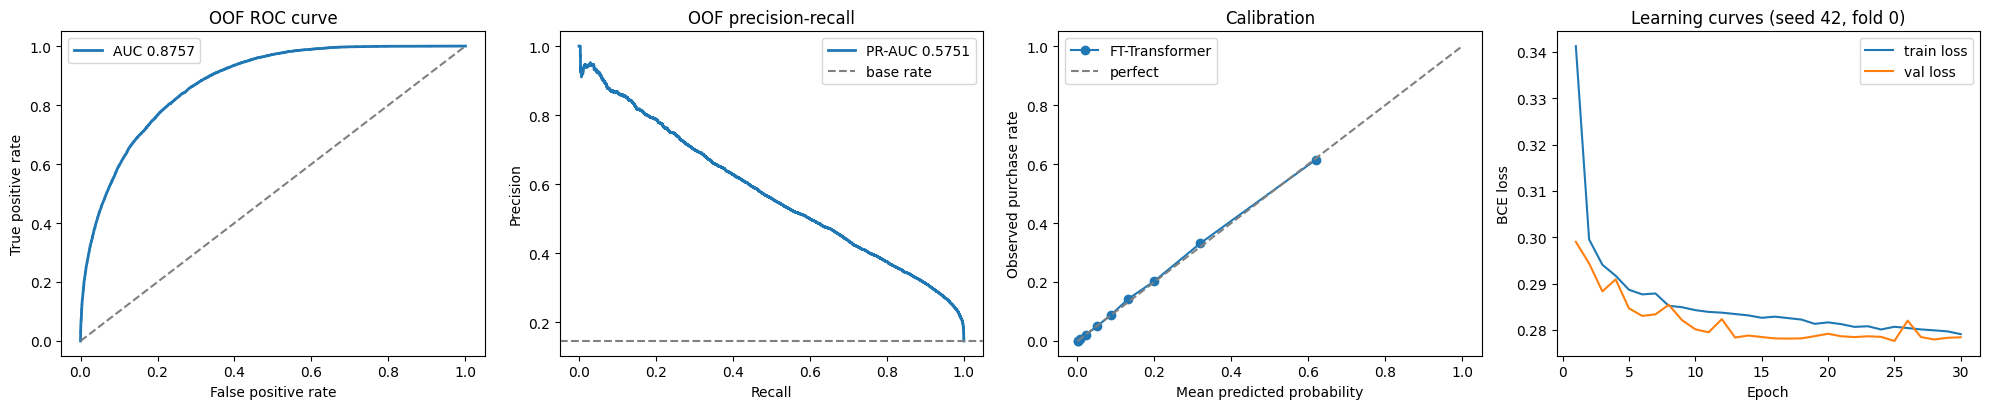

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))

fpr, tpr, _ = roc_curve(y, p)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC {overall['roc_auc']:.4f}"); ax[0].plot([0, 1], [0, 1], "--", c="grey")
ax[0].set(title="OOF ROC curve", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()

prec, rec, _ = precision_recall_curve(y, p)
ax[1].plot(rec, prec, lw=2, label=f"PR-AUC {overall['pr_auc']:.4f}"); ax[1].axhline(y.mean(), ls="--", c="grey", label="base rate")
ax[1].set(title="OOF precision-recall", xlabel="Recall", ylabel="Precision"); ax[1].legend()

# Reliability diagram: if the model is calibrated, points sit on the diagonal.
frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
ax[2].plot(mean_pred, frac_pos, "o-", label="FT-Transformer"); ax[2].plot([0, 1], [0, 1], "--", c="grey", label="perfect")
ax[2].set(title="Calibration", xlabel="Mean predicted probability", ylabel="Observed purchase rate"); ax[2].legend()

# Learning curves of the first trained model: the quickest way to diagnose over/under-fitting.
first_key = next(iter(histories)); h = pd.DataFrame(histories[first_key])
ax[3].plot(h.epoch, h.train_loss, label="train loss"); ax[3].plot(h.epoch, h.val_loss, label="val loss")
ax[3].set(title=f"Learning curves (seed {first_key[0]}, fold {first_key[1]})", xlabel="Epoch", ylabel="BCE loss"); ax[3].legend()

plt.tight_layout(); plt.savefig("artifacts/eval_plots.png", dpi=120); plt.show()

# Seed Noise Study for FT Transformer

In [10]:
# ================= SEED-NOISE STUDY (FT-Transformer) =================
# Each seed is scored on its OWN out-of-fold predictions (NOT on the seed-averaged ensemble above).
seed_rows = []
for si, seed in enumerate(cfg["seeds"]):
    p_s = oof[si]
    done_s = ~np.isnan(p_s)
    fd = fold_df[fold_df.seed == seed]
    seed_rows.append(dict(model="ft_transformer", seed=seed,
                          fold_mean_roc=fd.roc_auc.mean(), fold_mean_pr=fd.pr_auc.mean(),
                          pooled_roc=roc_auc_score(y_all[done_s], p_s[done_s]),
                          pooled_pr=average_precision_score(y_all[done_s], p_s[done_s]),
                          brier=brier_score_loss(y_all[done_s], p_s[done_s]),
                          logloss=log_loss(y_all[done_s], p_s[done_s]),
                          mean_best_iter=fd.best_epoch.mean()))
    pd.DataFrame({"customer_id": train[ID].values[done_s], "prob": p_s[done_s]}).to_csv(f"oof_ft_transformer_seed{seed}.csv", index=False)

seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv("seed_results_ft_transformer.csv", index=False)
fold_df[["seed", "fold", "roc_auc", "pr_auc", "best_epoch"]].to_csv("fold_results_ft_transformer_seeds.csv", index=False)
print("Per-seed results:"); print(seed_df.round(5).to_string(index=False))
print("\nMean and std across seeds:"); print(seed_df.drop(columns=["model", "seed"]).agg(["mean", "std"]).round(5))

Per-seed results:
         model  seed  fold_mean_roc  fold_mean_pr  pooled_roc  pooled_pr   brier  logloss  mean_best_iter
ft_transformer    42        0.87570       0.57515     0.87485    0.57274 0.08773  0.28189            19.8
ft_transformer    43        0.87515       0.57412     0.87447    0.57028 0.08794  0.28244            20.0
ft_transformer    44        0.87547       0.57491     0.87480    0.57211 0.08786  0.28208            19.8

Mean and std across seeds:
      fold_mean_roc  fold_mean_pr  pooled_roc  pooled_pr    brier  logloss  \
mean        0.87544       0.57473     0.87471    0.57171  0.08784  0.28214   
std         0.00028       0.00054     0.00021    0.00127  0.00011  0.00028   

      mean_best_iter  
mean        19.86667  
std          0.11547  


## 10. Code review cheat sheet

**Say it in one breath:** *"Each feature is turned into a learned vector (a token). A [CLS] token is added. Self-attention in 3 transformer blocks lets every token look at every other, and the [CLS] vector, which ends up summarising the whole customer, goes through a small head to give one logit. Sigmoid turns it into a purchase probability. We train with plain BCE and AdamW, stop early on validation ROC-AUC, and everything learned from data is fitted per fold."*

| Piece | What it does | What breaks if removed or changed |
|---|---|---|
| Shared `folds.csv` | identical splits across the team | scores are no longer comparable between models |
| Per-fold `TabularPreprocessor.fit` | statistics come only from the training fold | fitting on all data leaks validation info and inflates AUC |
| `log1p` + standardise + clip | puts inputs on comparable scales | heavy-tailed counts dominate, training becomes unstable or slow |
| Missing-value flags | keeps the "was missing" signal after imputation | the model cannot tell real zeros from missing |
| `FeatureTokenizer` | numeric: `x*W+b`; categorical: embedding lookup | the transformer has nothing to attend over |
| `cat_offsets` buffer | stops different categorical features sharing embedding rows | tier id 1 would share a vector with country id 1 |
| `[CLS]` token | the row summary that the head reads | you would need to pool tokens some other way |
| `norm_first`, residuals, dropout | stable training, regularisation | deeper models diverge or overfit |
| `model.train()` / `model.eval()` | dropout on while training, off when predicting | noisy, non-repeatable predictions |
| `zero_grad` then `backward` then `step` | the three-step learning cycle | gradients accumulate (no `zero_grad`), or nothing learns (no `step`) |
| `BCEWithLogitsLoss` | sigmoid + cross-entropy, stable | applying sigmoid AND this loss would apply sigmoid twice |
| `clip_grad_norm_` | caps huge updates | rare loss spikes |
| Early stopping + `load_state_dict(best)` | picks the best epoch, not the last | later, overfit weights are used |
| `torch.no_grad()` in prediction | skips gradient bookkeeping | slower and more memory, same results |

**Likely questions**
- *Why a transformer on a table?* It models feature interactions explicitly through attention; trees do it through splits, MLPs implicitly.
- *Why not class weights?* Imbalance is mild (14.6%), and weights would distort probabilities that the agent uses for expected-value decisions.
- *Why early stop on the validation fold?* Same rule as the LightGBM baseline, so the comparison is fair. It makes both scores slightly optimistic by the same mechanism, and this is disclosed in the report.
- *What would you not trust in production?* Calibration on new months (the data is one snapshot), the fixed `log1p` skew rule for new data, the unknown-category id for a new country, and the fact that SHAP explains the model, not causes.
- *Why is there a 0.38-style threshold?* Only for 0/1 files. The agent ranks by probability and cuts off by budget and offer cost.

**AI Use Log reminder:** if an AI assistant helped generate this notebook, log it: what you asked, what you accepted or changed, and **what you checked** (for example: shape check output, fold 0 score vs LightGBM, leakage rule per fold). Try at least one change yourself (for example `n_blocks` 3 to 2) and record the effect.